## Experiments: Recurrent Layers

Tom <br>
October __, 2026

This notebook tests how the recurrent layers affect the CNN-LSTM. Each experiment changes one parameter from the base model and compares the result on the validation set.

### How to Use This Notebook

- Build and run the base model first. Every experiment is compared with it, so it already covers the base value.
- Change one parameter at a time. Everything else stays at the base model.
- Before running an experiment, fill in the values you are testing, your hypothesis, why you chose those values, and the source that informed them.
- Judge results on validation accuracy and macro F1 only. The test set is saved for the final model.
- Fill in each results table, then the observations, insights and conclusion.

### Setup

#### _Early Stopping Configuration_

For the baseline and the first GRU experiment, we plotted the training and validation curves to observe the learning process and assess whether `patience=8` was sufficient.

For subsequent experiments, we increased patience to 30 and hid the detailed training outputs to keep the notebook concise. The larger patience allows training to continue through short-term fluctuations in validation loss, reducing the risk of stopping prematurely.

All experiments still use early stopping with `restore_best_weights=True`, so the final model weights are restored from the epoch with the lowest validation loss rather than the last training epoch.

In [1]:
import copy as cp
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from itertools import product
from IPython.display import display, HTML, Markdown
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from tensorflow.keras.layers import Input, LSTM, GRU, Dropout, Dense, SimpleRNN
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score

In [2]:
SEED = 8

def set_random_seed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)

In [3]:
# Locations of the shared data (relative to this notebook)
DATA_ROOT    = '../DATA'
FEATURE_PATH = DATA_ROOT + '/features'
MODEL_ROOT   = './models'

# Split names used in the feature file names and as dictionary keys
TRAIN      = 'train'
VALIDATION = 'val'
TEST       = 'test'


def load_data(backbone='resnet50', size=224, frames=16):
    """
    Load the precomputed CNN features and the labels for every split.

    Parameters:
        backbone: 'resnet50' or 'mobilenetv2'
        size:     input resolution the features were extracted at (224 or 112)
        frames:   frames per clip to keep (32, 16 or 8)

    Each saved clip has 32 evenly spaced frames, so fewer frames are made by
    keeping every 2nd (16) or every 4th (8) frame.

    Output:
        features: dict of float32 arrays shaped (clips, frames, feature size)
        labels:   dict of integer class labels (0-7)
    """
    step = 32 // frames
    features = {}
    labels   = {}

    # labels come from the shared splits file so everyone uses the same split
    label_data = np.load(f"{DATA_ROOT}/splits.npz")

    for name in [TRAIN, VALIDATION, TEST]:
        # features are saved as float16 to save space, so cast back for training
        x = np.load(f"{FEATURE_PATH}/{backbone}_{size}_{name}.npy").astype('float32')
        features[name] = x[:, ::step]
        labels[name]   = label_data[f'y_{name}']

    return (features, labels)


# Base model data: ResNet50, 224 px, 16 frames per clip
X, y = load_data('resnet50', 224, 16)

# Collects one row per run so the results tables can be printed
reports = []

for name in [TRAIN, VALIDATION, TEST]:
    print(name, X[name].shape, y[name].shape)

train (552, 16, 2048) (552,)
val (151, 16, 2048) (151,)
test (263, 16, 2048) (263,)


In [4]:
def filter_parameter_value(k, v):
    if k == 'Hidden layers':
        layers = []
        for layer in v:
            layers.append(f'{layer["fn"].__name__}({layer["units"]})')
        return layers
    elif k == 'Optimizer':
        return v.__name__
    return v

def config_to_html(conf, ignore_name=True):
    # html_str = ""
    # for k, v in conf.items():
    #     if ignore_name and (k == 'Experiment Name' or k == 'Setting'):
    #         continue
    #     if not isinstance(v, (int, float, str, tuple, list)):
    #         v = v.__name__
        # html_str += f'''<p><span style="display: inline-block; width:150px; text-align: right">{k}</span>: {v}</p>'''
    html_str = " | ".join(
        f"{k}={filter_parameter_value(k, v)}"
        for k, v in conf.items()
        if not (ignore_name and k in ('Experiment Name', 'Setting', 'prefix', 'stored model name'))
    )        
    return html_str

def print_report(df, title=''):
    styled_df = (df.style.hide()
                 .set_properties(**{'text-align': 'center'})
                 .set_table_styles([
                     { 'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')] }
                 ])
                )
    
    if len(title) > 0:
        display(Markdown(f'__{title}__'))
    display(styled_df)
    
class Line(object):
    def __init__(self, data, label):
        self.data = data
        self.label = label

class Lines(object):
    def __init__(self, title, lines, xlabel, ylabel):
        self._title = title
        self._lines = lines
        self._xlabel = xlabel
        self._ylable = ylabel

    def plot(self, ax):
        for line in self._lines:
            ax.plot(line.data, label=line.label)

        ax.set_xlabel(self._xlabel)
        ax.set_ylabel(self._ylable)
        ax.legend()

def plot_twins_multiple_line_chart(lines):
    _, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    for i in range(2):
        lines[i].plot(axes[i])

    plt.tight_layout()
    plt.show()
    

def plot_training_history(history):
    # plot accuracy
    # Training Accuracy
    train_acc = Line(history['accuracy'], 'Training Accuracy')
    # Validation Accuracy
    val_acc = Line(history['val_accuracy'], 'Validation Accuracy')
    acc_lines = Lines('Accuracy Trend',
                      lines=[train_acc, val_acc],
                      xlabel='Epoch',
                      ylabel='Accuracy')
    
    # plot loss
    # Training Loss
    train_loss = Line(history['loss'], 'Training Loss')
    # Validation Loss
    val_loss = Line(history['val_loss'], 'Validation Loss')
    loss_lines = Lines('Loss Trend',
                       lines=[train_loss, val_loss],
                       xlabel='Epoch',
                       ylabel='Loss')

    plot_twins_multiple_line_chart([acc_lines, loss_lines])

In [5]:
import time

class LatencyTracker(Callback):
    '''
        Keras callback that records how long each training epoch takes (in seconds).
    '''

    def on_train_begin(self, logs=None):
        # reset the counters at the start of every fit()
        self.epoch_times = []
        self.total_epochs = 0

    def on_epoch_begin(self, epoch, logs=None):
        # start the clock for this epoch
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        # stop the clock and store how long the epoch took
        duration = time.time() - self.epoch_start_time

        self.epoch_times.append(duration)
        self.total_epochs += 1

    @property
    def total_latency(self):
        # total training time across all epochs
        return sum(self.epoch_times)

In [6]:
def create_optimizer(params):
    '''
        Build the optimizer named in the settings dict
        (Adam is the base model's).
    '''
    if params['Optimizer'] == Adam:
        return Adam(learning_rate=params['Learning rate'])
    return None

def create_recurrent_layer(cfg, prefix, idx, ret_seq=False):
    return  cfg['fn'](cfg['units'],
                      activation=cfg['activation'],
                      recurrent_activation=cfg['recurrent_activation'],
                      recurrent_dropout=cfg['recurrent_dropout'],
                      name=get_layer_name(prefix, cfg, idx),
                      return_sequences=ret_seq)

def get_layer_name(prefix, layer, idx):
    layer_name = f'{prefix}_{layer["fn"].__name__.lower()}'
    if idx:
        layer_name += f'_{idx}'
    return layer_name

def measure_prediction_latency(model, X_clips, n_clips=100):
    '''
        Average time (ms) to predict ONE clip, the way the live demo would.
        
        Note: this times the recurrent part only, because the CNN features
              are precomputed.
    '''
    clips = tf.constant(X_clips[:n_clips])
    # warm-up call so setup time isn't counted
    model(clips[:1], training=False) 

    start = time.time()
    for i in range(n_clips):
        # direct call with a batch of 1 = one clip
        model(clips[i:i + 1], training=False)

    return (time.time() - start) / n_clips * 1000


def run_experiment(params, X, y, verbose=0):
    '''
        Build, train and evaluate one CNN-LSTM run, then add a row to `reports`.
    
        params: settings dict (copy of baseline_config with one value changed)
        X, y:   feature and label dicts from load_data()
        
        Results are judged on the validation set only; the test set is saved
        for the final model.
    '''
    if verbose == 0:
        # print experiment name only
        print(f"{params['Experiment Name']} ...", end=" ")
    start = time.time()

    # reset every random seed so the same settings always give the same result
    #tf.keras.utils.set_random_seed(SEED)
    set_random_seed(SEED)

    input_shape = X[TRAIN].shape[1:]   # (frames, feature size)
    
    # create model: recurrent layer -> dropout -> softmax output
    model = Sequential(name=params['Experiment Name'])
    model.add(Input(shape=input_shape))
    
    # for multiple recurrent layers
    hidden_layers = params['Hidden layers']
    layer_count = None
    if len(hidden_layers) > 1:
        layer_count = 1
        for layer in hidden_layers[:-1]:
            model.add(create_recurrent_layer(layer, params['prefix'], layer_count, True))
            layer_count += 1
    layer = hidden_layers[-1]
    model.add(create_recurrent_layer(layer, params['prefix'], layer_count))
    
    model.add(Dropout(params['Droupout rate'], name=f'{params["prefix"]}_dropout'))
    model.add(Dense(params['Output'][0], activation=params['Output'][1], name='output'))
    
    # compile model
    optimizer = create_optimizer(params)
    model.compile(
        optimizer=optimizer,
        loss = params['Loss'],
        metrics = params['Metrics']
    )

    if verbose > 0:
        model.summary()

    # early-stopping moniters the validation loss
    early_stopping = EarlyStopping(monitor=params['Moniter'],
                                   patience=params['patience'],
                                   restore_best_weights=params['restore best weights'])
    
    # checkpoint save the best model
    checkpoint = ModelCheckpoint(
        params['stored model name'],
        monitor=params['Moniter'],
        save_best_only=True
    )
    
    # latency-tracker calculates and records the duration per epoch
    latency_tracker = LatencyTracker()
    
    history = model.fit(X[TRAIN], y[TRAIN],
                        validation_data=(X[VALIDATION], y[VALIDATION]),
                        epochs = params['Epochs'],
                        batch_size = params['Batch size'],
                        callbacks = [early_stopping,
                                     checkpoint,
                                     latency_tracker],
                        verbose = verbose)
    
    # evaluate with testing data
    test_loss, test_accuracy = model.evaluate(X[TEST], y[TEST], verbose=verbose)
    
    # calculation for the report
    val_loss, val_accuracy   = model.evaluate(X[VALIDATION], y[VALIDATION], verbose=verbose)
    y_val_pred = np.argmax(model.predict(X[VALIDATION], verbose=verbose), axis=1)
    val_f1 = f1_score(y[VALIDATION], y_val_pred, average=params['F1 Average'])
    
    report = {
        'Val accuracy': val_accuracy,
        'Val macro F1': val_f1,
        'Test Accuracy': test_accuracy,
        'Test Loss': test_loss,
        'Epochs run': len(history.history['loss']),
        'Latency (ms)': measure_prediction_latency(model, X[VALIDATION], 1),
        'Train time (s)': latency_tracker.total_latency,
        'Parameters': config_to_html(params),
    }
    
    if verbose == 0:
        print(f'({time.time() - start:.2f}s)', end=" ... ")
        # print_report(pd.DataFrame([report]), params['Experiment Name'])
    else:
        print_report(pd.DataFrame([report]))
        plot_training_history(history.history)
        
    # clean the model to release memory
    del history
    del model
    
    return report

### Base Model

| Parameter | Base model |
|---|---|
| Backbone | ResNet50 (frozen, ImageNet weights) |
| Input resolution | 224 px |
| Frames per clip | 16 |
| Recurrent layer type | LSTM |
| Hidden units | 256 |
| Number of recurrent layers | 1 |
| Dropout placement | After the LSTM |
| Dropout rate | 0.5 |
| Output | Dense(8, softmax) |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss | Sparse categorical cross-entropy |
| Batch size | 32 |
| Epochs | Up to 100, early stopping on val loss (patience 8, restore best weights) |
| Seed | 8 |

In [7]:
baseline_config = {}
baseline_config['Experiment Name']     = "Baseline"
baseline_config['prefix']  = 'base'
baseline_config['Setting'] = "-"

#baseline_config['Recurrent layer'] = LSTM
baseline_config['Hidden layers']    = [{
    'fn': LSTM, 'units': 256,
    'activation': 'tanh',
    'recurrent_activation': 'sigmoid',
    'recurrent_dropout': 0.0
}]
baseline_config['Droupout rate']   = 0.5
baseline_config['Output']          = (8, "softmax")
baseline_config['Optimizer']       = Adam
baseline_config['Learning rate']   = 0.001
baseline_config['Loss']            = "sparse_categorical_crossentropy"
baseline_config['Metrics']         = ["accuracy"]
baseline_config['Batch size']      = 32
baseline_config['Epochs']          = 100
baseline_config['F1 Average']      = "macro"
baseline_config['Moniter']         = "val_loss"
baseline_config['patience']        = 8
baseline_config['restore best weights'] = True
baseline_config['stored model name']    = "baseline_tom.keras"

Model: "Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ base_lstm (LSTM)                │ (None, 256)            │     2,360,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ base_dropout (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,362,376 (9.01 MB)

 Trainable params: 2,362,376 (9.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.4348 - loss: 1.5544 - val_accuracy: 0.3642 - val_loss: 1.6378
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8388 - loss: 0.5905 - val_accuracy: 0.4305 - val_loss: 1.4558
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9293 - loss: 0.3510 - val_accuracy: 0.4172 - val_loss: 1.6664
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9728 - loss: 0.1963 - val_accuracy: 0.4702 - val_loss: 1.6191
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9873 - loss: 0.1157 - val_accuracy: 0.4503 - val_loss: 1.6433
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9964 - loss: 0.0806 - val_accuracy: 0.4570 - val_loss: 1.6657
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0494 - val_accuracy: 0.4768 - val_loss: 1.6929
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0243 - val_accuracy: 0.4305 - 

Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Latency (ms),Train time (s),Parameters
0.430464,0.468758,0.619772,1.130104,10,2.503633,2.326127,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=8 | restore best weights=True"


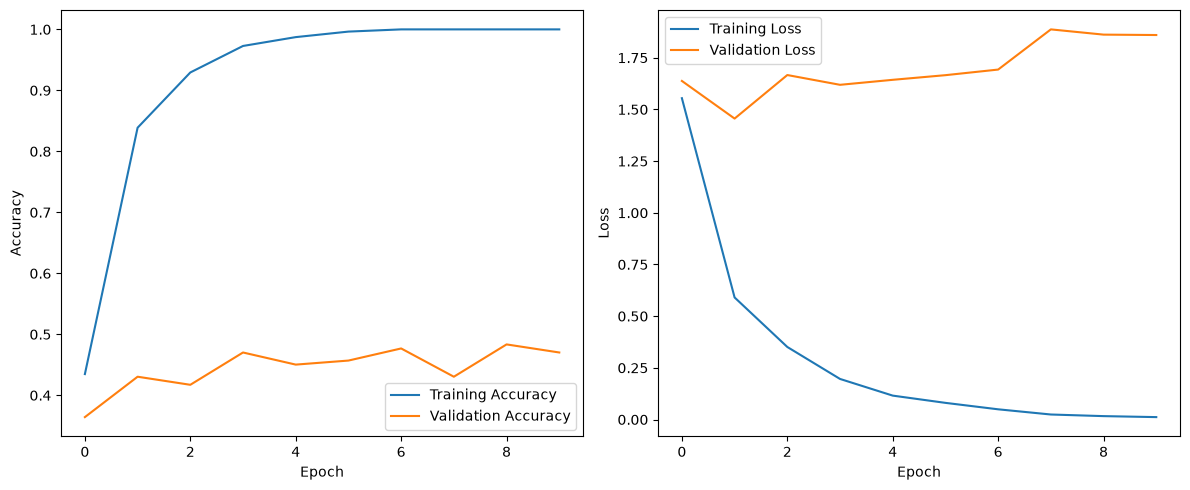

In [8]:
res = run_experiment(baseline_config, X, y, verbose=1)

res_ext = {
    'Run': baseline_config['Experiment Name'],
    'Setting': baseline_config['Setting']
}
res_ext.update(res)
reports.append(res_ext)

### Tuning Hyperparameters

| Parameter | Base model | Testing |
|---|---|---|
| Recurrent layer type | LSTM | ... |

- activation: __tanh__, relu, gelu, silu, linear
- recurrent_activation: __sigmoid__, hard_sigmoid, hard_silu, None
- recurrent_dropout: __0__, to 1.0 step 0.2


**Hypothesis:**

...

**Why these values:**

...

**Source:**
- [Keras GRU Layer](https://keras.io/api/layers/recurrent_layers/gru/)
- [Keras - Layer activation functions](https://keras.io/api/layers/activations/)

In [9]:
exp_count = 1
exp_results = []

act_opts = ['tanh', 'relu', 'gelu', 'silu', 'linear']
react_opts = ['sigmoid', 'hard_sigmoid', 'hard_silu', None]
redropout_opts = [n/10.0 for n in range(1, 11)]

for act, react, redropout in product(act_opts, react_opts, redropout_opts):
    cfg = cp.deepcopy(baseline_config)
    cfg['Experiment Name'] = f"Experiment_{exp_count:02d}"
    cfg['prefix'] = f"exp_{exp_count:02d}"
    cfg['Setting'] = f'{act}_{react}_{redropout}'
    hidden_layer = cfg['Hidden layers'][0]
    hidden_layer['activation'] = act
    hidden_layer['recurrent_activation'] = react
    hidden_layer['recurrent_dropout'] = redropout
    cfg['patience'] = 30

    #print(f'{cfg['Experiment Name']}: {cfg['Setting']}')
    exp_count += 1
    res = run_experiment(cfg, X, y, verbose=0)
    res_ext = {
        'Run': cfg['Experiment Name'],
        'Setting': cfg['Setting']
    }
    res_ext.update(res)
    exp_results.append(res_ext)
    
reports.extend(exp_results)

Experiment_01 ... (8.16s) ... Experiment_02 ... WARNING:tensorflow:5 out of the last 11 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x71be34588720> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
(7.79s) ... Experiment_03 ... (8.20s) ... Experiment_04 ... (8.39s) ... Experiment_05 ... (8.06s) ... Experiment_06 ... (9.06s) ... Experiment_07 ... (8.42s) ... Experiment_08 ... (8.37s) ... Experiment_09 ... (8.48s) ... Experim

#### Results

In [10]:
print_report(pd.DataFrame(exp_results).sort_values(by=['Val accuracy', 'Val macro F1'], ascending=[False, False])[:20])

Run,Setting,Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Latency (ms),Train time (s),Parameters
Experiment_41,relu_sigmoid_0.1,0.569536,0.581580,0.574144,1.400794,34,28.799057,5.660312,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_131,silu_hard_sigmoid_0.1,0.543046,0.557556,0.631179,1.508747,36,32.659769,6.026382,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_134,silu_hard_sigmoid_0.4,0.536424,0.523777,0.612167,1.581556,34,32.751322,6.108919,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_130,silu_sigmoid_1.0,0.529801,0.527643,0.596958,1.661911,37,28.797626,5.235940,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_06,tanh_sigmoid_0.6,0.523179,0.527005,0.619772,1.081182,37,27.366161,8.579736,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_87,gelu_sigmoid_0.7,0.523179,0.526431,0.646388,1.158296,46,29.535294,7.590733,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_08,tanh_sigmoid_0.8,0.516556,0.540542,0.619772,0.987415,34,28.048038,7.908571,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_11,tanh_hard_sigmoid_0.1,0.516556,0.531140,0.688213,1.011154,33,29.039145,8.722598,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_42,relu_sigmoid_0.2,0.516556,0.516708,0.486692,1.866166,54,28.199196,7.410989,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_126,silu_sigmoid_0.6,0.516556,0.508851,0.562738,1.534284,37,31.424284,6.141440,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"


#### Observations

The baseline LSTM achieved `42.38%` validation accuracy and a macro F1-score of `0.45106`. Replacing it with GRU improved validation accuracy to `47.02%` and macro F1-score to `0.48893`.

The GRU model also reduced trainable parameters from `2,362,376` to `1,773,064`, approximately `25%` fewer.

#### Insights

GRU achieved better validation performance with fewer parameters. Since our training dataset contains only `552` video clips, a simpler recurrent architecture may generalize better.

Both LSTM and GRU use gates to learn temporal dependencies. However, our input sequences contain only `16` frames, so the additional complexity of LSTM may not provide a significant advantage.

The results suggest that GRU is a promising alternative for our video classification task. Also, the improvement from one experiment is not enough to establish that GRU is always better.

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| GRU | Yes, provisionally | Higher validation accuracy and macro F1, with fewer trainable parameters than LSTM |

### Hidden Units

| Parameter | Base model | Testing |
|---|---|---|
| Hidden units | 256 | 64, 128, 192, 384 |

**Hypothesis:**

Expect to find the number of hidden units improving performance because the current models show overfitting.

**Why these values:**

The values `64`, `128`, `192`, and `384` allow us to compare different model capacities while keeping the same GRU architecture.

**Source:** Course knowledge about hyperparameter tuning and overfitting.

In [11]:
hidden_units = [64, 128, 192, 384]
act_opts = ['tanh', 'relu', 'gelu', 'silu', 'linear']
react_opts = ['sigmoid', 'hard_sigmoid']
redropout_opts = [n/10.0 for n in range(2, 11)]

for size, act, react, redropout in product(hidden_units, act_opts, react_opts, redropout_opts):
    cfg = cp.deepcopy(baseline_config)
    cfg['Experiment Name'] = f"Experiment_{exp_count:02d}"
    cfg['prefix'] = f"exp_{exp_count:02d}"
    cfg['Setting'] = f'{act}_{react}_{redropout}'
    hidden_layer = cfg['Hidden layers'][0]
    hidden_layer['units'] = size
    hidden_layer['activation'] = act
    hidden_layer['recurrent_activation'] = react
    hidden_layer['recurrent_dropout'] = redropout
    cfg['patience'] = 30

    #print(f'{cfg['Experiment Name']}: {cfg['Setting']}')
    exp_count += 1
    res = run_experiment(cfg, X, y, verbose=0)
    res_ext = {
        'Run': cfg['Experiment Name'],
        'Setting': cfg['Setting']
    }
    res_ext.update(res)
    exp_results.append(res_ext)
    
reports.extend(exp_results)

Experiment_201 ... (8.66s) ... Experiment_202 ... (9.20s) ... Experiment_203 ... (8.62s) ... Experiment_204 ... (8.87s) ... Experiment_205 ... (8.46s) ... Experiment_206 ... (9.76s) ... Experiment_207 ... (11.64s) ... Experiment_208 ... (9.51s) ... Experiment_209 ... (10.33s) ... Experiment_210 ... (9.87s) ... Experiment_211 ... (6.60s) ... Experiment_212 ... (6.72s) ... Experiment_213 ... (6.66s) ... Experiment_214 ... (7.25s) ... Experiment_215 ... (6.25s) ... Experiment_216 ... (6.90s) ... Experiment_217 ... (6.44s) ... Experiment_218 ... (5.98s) ... Experiment_219 ... (8.87s) ... Experiment_220 ... (6.66s) ... Experiment_221 ... (6.89s) ... Experiment_222 ... (7.25s) ... Experiment_223 ... (8.99s) ... Experiment_224 ... (8.93s) ... Experiment_225 ... (7.07s) ... Experiment_226 ... (11.73s) ... Experiment_227 ... (5.38s) ... Experiment_228 ... (7.47s) ... Experiment_229 ... (6.71s) ... Experiment_230 ... (9.20s) ... Experiment_231 ... (7.87s) ... Experiment_232 ... (6.99s) ... Exper

#### Results

In [12]:
print_report(pd.DataFrame(exp_results).sort_values(by=['Val accuracy', 'Val macro F1'], ascending=[False, False])[:20])

Run,Setting,Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Latency (ms),Train time (s),Parameters
Experiment_214,tanh_hard_sigmoid_0.6,0.576159,0.602539,0.642586,0.982365,46,29.090166,6.462347,"Hidden layers=['LSTM(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_216,tanh_hard_sigmoid_0.8,0.576159,0.589556,0.619772,1.026923,42,28.980732,6.107641,"Hidden layers=['LSTM(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_41,relu_sigmoid_0.1,0.569536,0.581580,0.574144,1.400794,34,28.799057,5.660312,"Hidden layers=['LSTM(256)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_400,relu_sigmoid_0.3,0.569536,0.569957,0.600760,1.798239,35,27.866125,5.556911,"Hidden layers=['LSTM(192)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_209,tanh_sigmoid_1.0,0.556291,0.573424,0.650190,0.969041,47,24.587393,9.865995,"Hidden layers=['LSTM(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_394,tanh_hard_sigmoid_0.6,0.556291,0.572223,0.642586,0.975873,36,29.081106,5.794820,"Hidden layers=['LSTM(192)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_444,silu_hard_sigmoid_0.2,0.549669,0.551380,0.593156,1.470770,35,32.993317,5.853980,"Hidden layers=['LSTM(192)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_502,relu_hard_sigmoid_0.6,0.549669,0.546308,0.532319,1.520745,60,29.034138,8.654419,"Hidden layers=['LSTM(384)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_231,relu_hard_sigmoid_0.5,0.549669,0.528518,0.615970,1.419629,42,29.592514,6.983925,"Hidden layers=['LSTM(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_206,tanh_sigmoid_0.7,0.543046,0.563823,0.615970,1.058298,43,27.081251,9.290136,"Hidden layers=['LSTM(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"


#### Observations

- All four GRU configurations outperformed the LSTM baseline in validation accuracy and macro F1.
- Performance generally improved from `64` to `192` hidden units, but decreased when the number increased to `384`.
- The 192-unit GRU achieved the best validation accuracy of `54.97%`, approximately `12.58` percentage points higher than the baseline.

#### Insights

The results show that increasing hidden units does not always improve performance. With only `64` or `128` hidden units, the model may have insufficient capacity to capture all the temporal patterns needed to distinguish the eight action classes. Increasing to `192` units improved performance, suggesting that additional capacity helped the model learn more useful patterns.

However, compare to `256` and `384` units, more units reduced validation performance. This may indicate overfitting or optimization difficulties. Our dataset contains relatively few training videos, while each frame is represented by `2,048` CNN features, making it possible for a large recurrent model to learn patterns that do not generalize well.

This demonstrates the relationship between model capacity, generalization and overfitting discussed in class.

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| 192 hidden units | Yes | Highest validation accuracy and macro F1 among tested single-layer GRU configurations. |

### Number of Recurrent Layers

| Parameter | Base model | Testing |
|---|---|---|
| Number of recurrent layers | 1 | two and three recurrent layers using LSTM, GRU, and SimpleRNN, including mixed recurrent architectures |

**Hypothesis:**

Expect increasing the number of recurrent layers to improve validation performance because deepter recurrent networks can learn more complex temporal representations. However, additional layers also increase model complexity and may cause overfitting, particularly with our relatively small dataset.

**Why these values:**

The baseline contains on LSTM layer, and the following experiment works with a single GRU layer. Testing multiple recurrent layers allows us to investigate whether increasing network depth improves classification performance.

We use LSTM, GRU, and SimpleRNN to explore both homogeneous and mixed recurrent architectures. The first layer contains `64`, `128`, `192`, or `256` hidden units, while each subsequent layer contains half as many units.

This provides different model capacities and allows us investigate how network depth and recurrent layer combinations affect performance.

**Source:** Course knowledge about RNN, model complexity, deep learning architectures, model complexity, and overfitting.

#### _Two Recurrent Layers_

In [14]:
layer_types = [LSTM, GRU, SimpleRNN]
layer_units = [64, 128, 192, 256]
exp_results2 = []

for layer1, layer2, units in product(layer_types, layer_types, layer_units):
    exp_count += 1
    cfg = cp.deepcopy(baseline_config)
    r1 = units
    r2 = int(r1/2)
    cfg['Experiment Name'] = f"Experiment_{exp_count:02d}"
    cfg['prefix']  = f'exp_{exp_count:02d}'
    cfg['Setting'] = f'{layer1.__name__}({r1}) + {layer2.__name__}({r2})'
    cfg['Hidden layers'] = [
        { "fn": layer1, "units": r1 },
        { "fn": layer2, "units": r2 }
    ]
    #cfg['Dropout rate'] = 0.4
    cfg['patience'] = 30
    
    res = run_experiment(cfg, X, y, verbose=0)
    res_ext = {
        'Run': cfg['Experiment Name'],
        'Setting': cfg['Setting']
    }
    res_ext.update(res)
    exp_results2.append(res_ext)
    
reports.extend(exp_results2)

print_report(pd.DataFrame(exp_results2).sort_values(by=['Val accuracy', 'Val macro F1'], ascending=[False, False])[:10])

Experiment_10 ... (5.05s) ... Experiment_11 ... (5.99s) ... Experiment_12 ... (7.84s) ... Experiment_13 ... (9.41s) ... Experiment_14 ... (5.29s) ... Experiment_15 ... (6.29s) ... Experiment_16 ... (7.86s) ... Experiment_17 ... (9.57s) ... Experiment_18 ... (4.66s) ... Experiment_19 ... (6.06s) ... Experiment_20 ... (7.18s) ... Experiment_21 ... (8.42s) ... Experiment_22 ... (4.84s) ... Experiment_23 ... (5.66s) ... Experiment_24 ... (7.59s) ... Experiment_25 ... (9.35s) ... Experiment_26 ... (4.75s) ... Experiment_27 ... (5.85s) ... Experiment_28 ... (7.42s) ... Experiment_29 ... (8.87s) ... Experiment_30 ... (4.10s) ... Experiment_31 ... (5.51s) ... Experiment_32 ... (6.39s) ... Experiment_33 ... (7.58s) ... Experiment_34 ... (3.61s) ... Experiment_35 ... (4.19s) ... Experiment_36 ... (5.12s) ... Experiment_37 ... (6.48s) ... Experiment_38 ... (3.77s) ... Experiment_39 ... (4.35s) ... Experiment_40 ... (5.15s) ... Experiment_41 ... (6.19s) ... Experiment_42 ... (3.35s) ... Experiment

Run,Setting,Val accuracy,Val macro F1,Test Accuracy,Test Loss,Epochs run,Latency (ms),Train time (s),Parameters
Experiment_17,LSTM(256) + GRU(128),0.516556,0.543280,0.566540,1.218042,32,26.491165,9.168751,"Hidden layers=['LSTM(256)', 'GRU(128)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_38,SimpleRNN(64) + GRU(32),0.516556,0.537085,0.638783,1.196791,33,20.403147,3.484256,"Hidden layers=['SimpleRNN(64)', 'GRU(32)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_25,GRU(256) + LSTM(128),0.503311,0.513242,0.600760,1.150451,32,26.293993,8.958283,"Hidden layers=['GRU(256)', 'LSTM(128)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_36,SimpleRNN(192) + LSTM(96),0.503311,0.484885,0.623574,1.081357,32,20.061970,4.820676,"Hidden layers=['SimpleRNN(192)', 'LSTM(96)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_35,SimpleRNN(128) + LSTM(64),0.483444,0.493610,0.528517,1.250476,32,17.718077,3.917227,"Hidden layers=['SimpleRNN(128)', 'LSTM(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_20,LSTM(192) + SimpleRNN(96),0.483444,0.463264,0.615970,1.206589,32,20.176888,6.707855,"Hidden layers=['LSTM(192)', 'SimpleRNN(96)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_28,GRU(192) + GRU(96),0.476821,0.496340,0.608365,1.080375,32,29.649258,7.033101,"Hidden layers=['GRU(192)', 'GRU(96)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_42,SimpleRNN(64) + SimpleRNN(32),0.476821,0.476405,0.543726,1.332007,34,14.760256,3.100919,"Hidden layers=['SimpleRNN(64)', 'SimpleRNN(32)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_43,SimpleRNN(128) + SimpleRNN(64),0.456954,0.452738,0.627376,1.177970,35,15.258074,3.905665,"Hidden layers=['SimpleRNN(128)', 'SimpleRNN(64)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=macro | Moniter=val_loss | patience=30 | restore best weights=True"
Experiment_14,LSTM(64) + GRU(32),0.450331,0.463823,0.650190,1.119304,35,23.448944,4.969170,"Hidden layers=['LSTM(64)', 'GRU(32)'] | Droupout rate=0.5 | Output=(8, 'softmax') | Optimizer=Adam | Learning rate=0.001 | Loss=sparse_categorical_crossentropy | Metrics=['accuracy'] | Batch size=32 | Epochs=100 | F1 Average=

#### _Three Recurrent Layers_

In [ ]:
# Three recurrent layers
layer_types = [LSTM, GRU, SimpleRNN]
layer_units = [64, 128, 192, 256]
exp_results3 = []

for layer1, layer2, layer3, units in product(layer_types, layer_types, layer_types, layer_units):
    exp_count += 1
    cfg = cp.deepcopy(baseline_config)
    r1 = units
    r2 = int(r1/2)
    r3 = int(r2/2)
    cfg['Experiment Name'] = f"Experiment_{exp_count:02d}"
    cfg['prefix']  = f'exp_{exp_count:02d}'
    cfg['Setting'] = f'{layer1.__name__}({r1}) + {layer2.__name__}({r2}) + {layer3.__name__}({r3})'
    cfg['Hidden layers'] = [
        { "fn": layer1, "units": r1 },
        { "fn": layer2, "units": r2 },
        { "fn": layer3, "units": r3 }
    ]
    #cfg['Dropout rate'] = 0.4
    cfg['patience'] = 30
    
    res = run_experiment(cfg, X, y, verbose=0)
    res_ext = {
        'Run': cfg['Experiment Name'],
        'Setting': cfg['Setting']
    }
    res_ext.update(res)
    exp_results3.append(res_ext)

reports.extend(exp_results3)

print_report(pd.DataFrame(exp_results3).sort_values(by=['Val accuracy', 'Val macro F1'], ascending=[False, False])[:10])

Experiment_46 ... (6.82s) ... Experiment_47 ... (7.17s) ... Experiment_48 ... (8.79s) ... Experiment_49 ... (11.17s) ... Experiment_50 ... (6.08s) ... Experiment_51 ... (7.63s) ... Experiment_52 ... (8.82s) ... Experiment_53 ... (10.88s) ... Experiment_54 ... (6.02s) ... Experiment_55 ... (7.23s) ... Experiment_56 ... (8.40s) ... Experiment_57 ... (10.27s) ... Experiment_58 ... (5.92s) ... Experiment_59 ... (7.68s) ... Experiment_60 ... (8.98s) ... Experiment_61 ... (10.66s) ... Experiment_62 ... (6.36s) ... Experiment_63 ... (8.17s) ... Experiment_64 ... (9.29s) ... Experiment_65 ... (10.56s) ... Experiment_66 ... (5.85s) ... Experiment_67 ... (7.15s) ... Experiment_68 ... (8.63s) ... Experiment_69 ... (10.74s) ... Experiment_70 ... (5.62s) ... Experiment_71 ... (6.99s) ... Experiment_72 ... (7.84s) ... Experiment_73 ... (9.47s) ... Experiment_74 ... (5.71s) ... Experiment_75 ... (7.07s) ... Experiment_76 ... (8.16s) ... Experiment_77 ... (9.72s) ... Experiment_78 ... (5.14s) ... Expe

W0000 00:00:1794844536.811837 4827969 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1794844486015692000 in buffer 'PrefetchDataset' sat unconsumed for 50.7961 seconds!


#### Results

In [ ]:
print_report(pd.DataFrame(reports).sort_values(by=['Val accuracy', 'Val macro F1'], ascending=[False, False])[:15])

#### Observations

The experiments show that increasing the number of recurrent layers can improve validation performance, although the improvement depends on the architecture and hidden-unit configuration.

- The best single-layer model, `GRU(192)`, achieved `54.97%` validation accuracy and a macro F1-score of `0.56292`.
- The best two-layer model, `GRU(256)+GRU(128)`, achieved `54.30%` validation accuracy and a macro F1-score of `0.54225`. This was slightly lower than the best single-layer model.
- The three-layer experiments produced __better__ results:
  - `SimpleRNN(128)+GRU(64)+GRU(32)` achieved the highest validation accuracy of `60.26%` and macro F1-score of `0.604`.
  - `GRU(128)+GRU(64)+SimpleRNN(32)` achieved `56.95%` validation accuracy and macro F1 of `0.59076`.
  - `GRU(192)+GRU(96)+LSTM(48)` also achieved `56.95%` validation accuracy, with macro F1 of `0.56881`.

The best three-layer model improved validation accuracy by `17.88` percentage points compared with the original LSTM baseline.

These results suggest that deeper recurrent architectures can improve performance, but not every three-layer configuration outperformed the simpler models.

#### Insights

Stacking recurrent layers allows the model to learn temporal representations at multiple levels. Earlier layers process the sequence of CNN features, while subsequent layers learn from the representations produced by previous recurrent layers.

Our dataset contains only `552` training clips, with 16 frames per clip and `2,048` extracted features per frame. Although the sequences are relatively short, the extracted features contain substantial visual information. Additional recurrent layers may help the model transform these features into more useful representations for action classification.

Interestingly, the best configuration combines SimpleRNN and GRU rather than using only one recurrent layer type. SimpleRNN has a simpler structure, while GRU uses gates to control information flow. Their combination may help the network learn complementary temporal representations.

However, the best two-layer model did not outperform the best single-layer model, and some three-layer configurations performed worse than simpler alternatives.

This suggests that increasing network depth alone does not guarantee better performance. The arrangement of recurrent layers and their hidden-unit sizes also affects generalization.

The results demonstrate the importance of experimental hyperparameter tuning discussed in class. A more complex model can provide better performance, but its effectiveness must be evaluated using validation data rather than assumed from its architecture.

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| SimpleRNN(128) + GRU(64) + GRU(32) | Yes, provisionally | Highest validation accuracy (`60.26%`) and macro F1 (`0.604`) among all tested configurations |

The three-layer configuration achieved better validation performance than the best single-layer and two-layer models. Therefore, it is the most promising architecture for further investigation.

However, the improvement does not mean that deeper models are always better. Additional experiments may be needed to confirm whether the result is consistent across different training runs.reports.extend(exp_results2)

print_report(pd.DataFrame(exp_results2).sort_values(by=['Val accuracy', 'Val macro F1'], ascending=[False, False])[:10])

### Summary

| Experiment | Best value | Carry forward? | Reason |
|---|---|---|---|
| Recurrent Layer Type | GRU | Yes, for single-layer comparison | Better validation performance with fewer parameters than the baseline |
| Hidden Units | 192 (single GRU) | Yes, as a comparison model | Best single-layer configuration |
| Number of Recurrent Layers | 3: SimpleRNN(128) + GRU(64) + GRU(32) | Yes | Best overall validation accuracy and macro F1 |

#### Overall Conclusions

The experiments demonstrate that recurrent layer type, hidden-unit size, network depth, and layer combinations affect video classification performance.

For single-layer architectures, GRU(192) achieved the best validation performance, with `54.97%` accuracy and macro F1-score of `0.56292`.

Although two-layer recurrent models improved performance over the original baseline, they did not outperform the best single-layer model.

However, the three-layer experiments achieved further improvements. The combination `SimpleRNN(128) + GRU(64) + GRU(32)` achieved the highest validation accuracy of `60.26%` and macro F1-score of `0.604`.

These reults suggest that combining different recurrent architectures can be beneficial for learning temporal representations from pretrained CNN features.

Based on the current results, the three-layer `SimpleRNN-GRU-GRU` model is the most promising candidate for further evaluation.

Nevertheless, the experiments also demonstrate that increasing model complexity does not consistantly improve performance. Selecting an effective architecture requires balancing model capacity and generalization.